In [31]:
import scanpy as sc
import pandas as pd
import numpy as np
import random
import sys

sys.path.append("../../../atlas_extension/mapqc/")
import mapqc
import plotting

In [2]:
%load_ext lab_black

In [3]:
atlas_path = "../../data/HLCA_full_v1.1_emb.h5ad"

In [4]:
adata_full = sc.read_h5ad(atlas_path)

subset to query batch of choice:

In [15]:
query_batch = "Banovich_Kropski_2020"

In [7]:
adata = adata_full[
    (adata_full.obs.core_or_extension == "core")
    | (adata_full.obs.dataset == query_batch)
].copy()

add precalculated umap coordinates:

In [9]:
umap_coords = pd.read_csv(f"./umaps/{query_batch}_umap.csv", index_col=0)

In [10]:
adata.obsm["X_umap"] = umap_coords.loc[adata.obs.index, :].values

### Prepare adata:

In [18]:
ref_q_key = "core_or_extension"
batch_key = "dataset"
ref_cat = "core"
query_cat = "extension"
condition_key = "lung_condition"

In [17]:
if query_batch in (adata.obs.loc[adata.obs[ref_q_key] == ref_cat, batch_key].values):
    print(f"Setting batch {query_batch} to 'query' as query simulation.")
    adata.obs[ref_q_key] = adata.obs[ref_q_key].tolist()
    adata.obs.loc[adata.obs[batch_key] == query_batch, ref_q_key] = query_cat

Setting batch Banovich_Kropski_2020 to 'query' as query simulation.


In [19]:
adata.obs.loc[adata.obs.dataset == query_dataset, condition_key].unique()

['Healthy', 'Sarcoidosis', 'IPF', 'ILD', 'HP', 'NSIP']
Categories (7, object): ['HP', 'Healthy', 'Healthy (tumor adjacent)', 'ILD', 'IPF', 'NSIP', 'Sarcoidosis']

In [20]:
condition_of_interest = "Healthy"
print(f"Subsetting query to condition {condition_of_interest}")
adata_healthy = adata[
    (adata.obs[ref_q_key] == ref_cat)
    | (adata.obs[condition_key] == condition_of_interest)
].copy()

Subsetting query to condition Healthy


In [33]:
condition_of_interest = "IPF"
print(f"Subsetting query to condition {condition_of_interest}")
adata_disease = adata[
    (adata.obs[ref_q_key] == ref_cat)
    | (adata.obs[condition_key] == condition_of_interest)
].copy()

Subsetting query to condition IPF


### Run mapQC on healthy:

In [247]:
imp.reload(mapqc)

<module 'mapqc' from '../../../atlas_extension/mapqc/mapqc.py'>

In [248]:
n_nhoods = 100
k = 1000

In [249]:
query_cell_idc_healthy = np.where(adata_healthy.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_healthy = random.sample(query_cell_idc_healthy, k=n_nhoods)
center_cells_healthy = np.array(
    adata_healthy.obs.iloc[center_cell_idc_healthy, :].index
)

In [250]:
results_healthy = mapqc.mapQC_results(
    adata=adata_healthy,
    center_cells=center_cells_healthy,
    k=k,
    ref_q_key="core_or_extension",
    ref_cat="core",
    query_cat="extension",
)

In [251]:
results_healthy.calculate_sample_dists_to_ref_samples()

../../../atlas_extension/mapqc/mapqc.py:163: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
../../../atlas_extension/mapqc/mapqc.py:167: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = nhood_ref_mean = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [252]:
results_healthy.calculate_nhood_statistics()

93% of neighborhoods passed filtering.
12% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.


../../../atlas_extension/mapqc/mapqc.py:232: RuntimeWarning: Mean of empty slice
  # TO DO


In [253]:
results_healthy.nhood_stats

,ks_stat,pval,nhood_number,nhood_weight,pval_corr,sign,mean_zscored_q_dist_to_ref
GCTGCGAAGGCAGTCA_F01641,0.345455,0.174987,0,0.882500,0.359269,False,0.491300
CTACACCTCGTCACGG_F02528,0.306034,0.253919,1,0.947500,0.475472,False,0.614481
CTACACCTCCATGAAC_F02524,0.4125,0.091928,2,0.857333,0.231214,False,0.827632
GCAAACTTCGTTACGA_F02509,0.104167,0.744389,3,0.948833,0.885923,False,-0.238793
GGACGTCAGCCAGTAG_F02526,0.455128,0.045667,4,0.907500,0.178513,False,0.975617
...,...,...,...,...,...,...,...
CCATGTCCACGCCAGT_F01851,0.172727,0.594541,95,0.762483,0.761463,False,0.064333
GCTCTGTCATGGTCTA_F02611,0.288889,0.363366,96,0.892333,0.605064,False,-0.425025
CCGTACTAGGACATTA_F02522,0.238095,0.352202,97,0.792250,0.600665,False,0.200560
TATGCCCTCCGCGTTT_F02617,0.158088,0.581206,98,0.995333,0.761463,False,-0.242192


### Optional: run mapQC on disease

In [254]:
query_cell_idc_disease = np.where(adata_disease.obs[ref_q_key] == query_cat)[0].tolist()
random.seed(0)
center_cell_idc_disease = random.sample(query_cell_idc_disease, k=n_nhoods)
center_cells_disease = np.array(
    adata_disease.obs.iloc[center_cell_idc_disease, :].index
)

In [255]:
results_disease = mapqc.mapQC_results(
    adata=adata_disease,
    center_cells=center_cells_disease,
    k=k,
    ref_q_key="core_or_extension",
    ref_cat="core",
    query_cat="extension",
)

In [256]:
results_disease.calculate_sample_dists_to_ref_samples()

../../../atlas_extension/mapqc/mapqc.py:163: RuntimeWarning: Mean of empty slice
  self.mean_sample_dists_to_ref = np.nanmean(self.intersample_distances, axis=0)
../../../atlas_extension/mapqc/mapqc.py:167: RuntimeWarning: Mean of empty slice
  nhood_ref_mean_dists = nhood_ref_mean = np.nanmean(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/numpy/lib/nanfunctions.py:1872: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [257]:
results_disease.calculate_nhood_statistics()

83% of neighborhoods passed filtering.
67% of neighborhoods that passed filtering are below the significance threshold alpha=0.05.


../../../atlas_extension/mapqc/mapqc.py:232: RuntimeWarning: Mean of empty slice
  # TO DO


### Plot:

#### healthy:

In [258]:
imp.reload(plotting)

<module 'plotting' from '../../../atlas_extension/mapqc/plotting.py'>

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


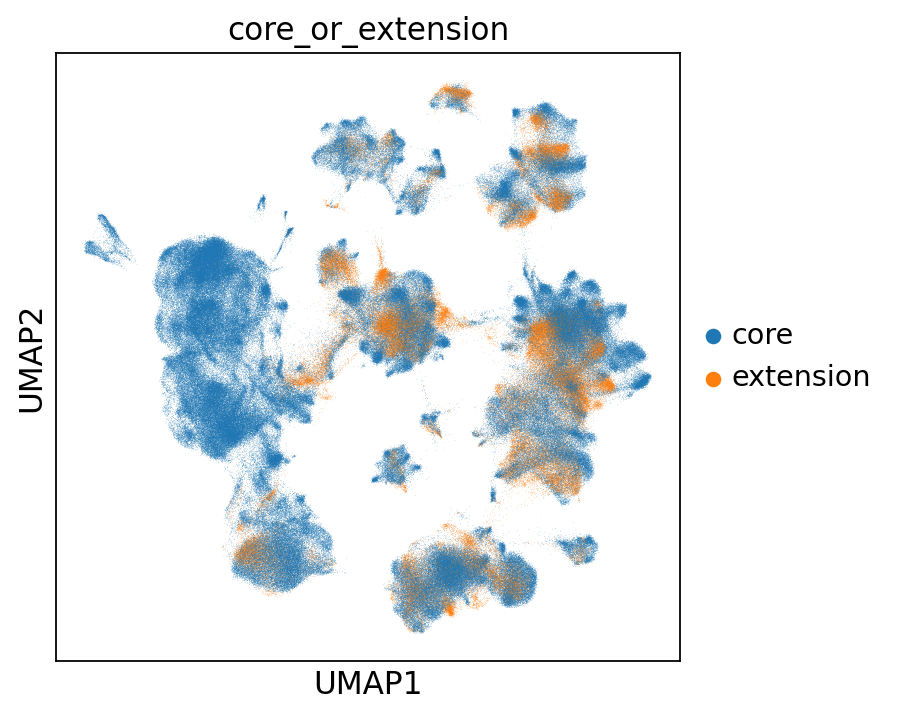

In [259]:
sc.pl.umap(results_healthy.adata, color="core_or_extension")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


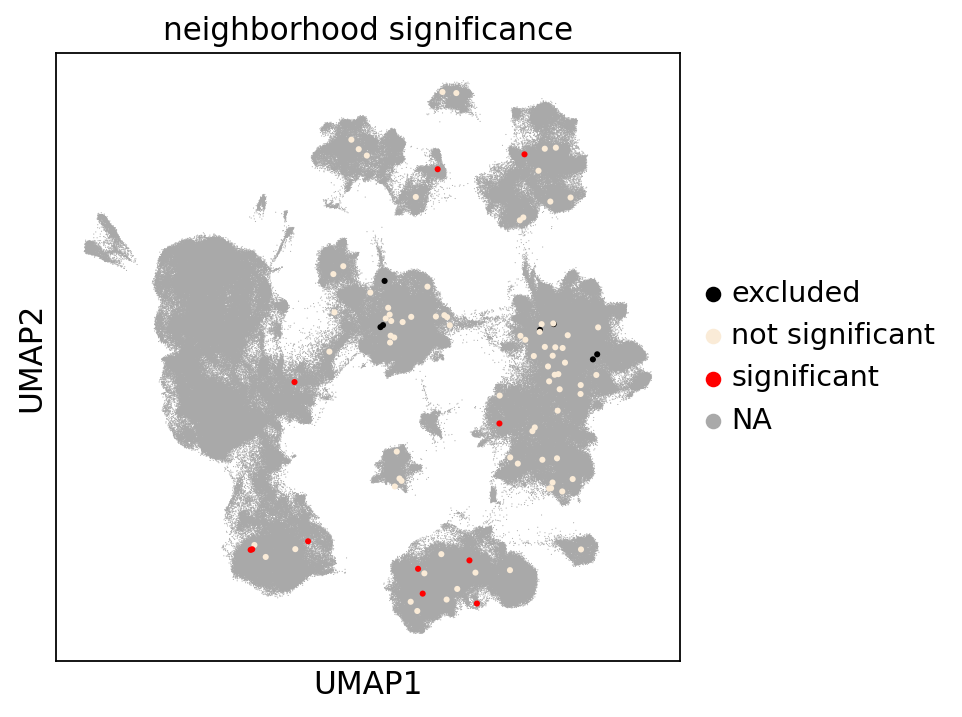

In [262]:
plotting.plot_umap_significance(results_healthy)

../../../atlas_extension/mapqc/plotting.py:210: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  title = f"Cells from neighborhood {neighborhood}"
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


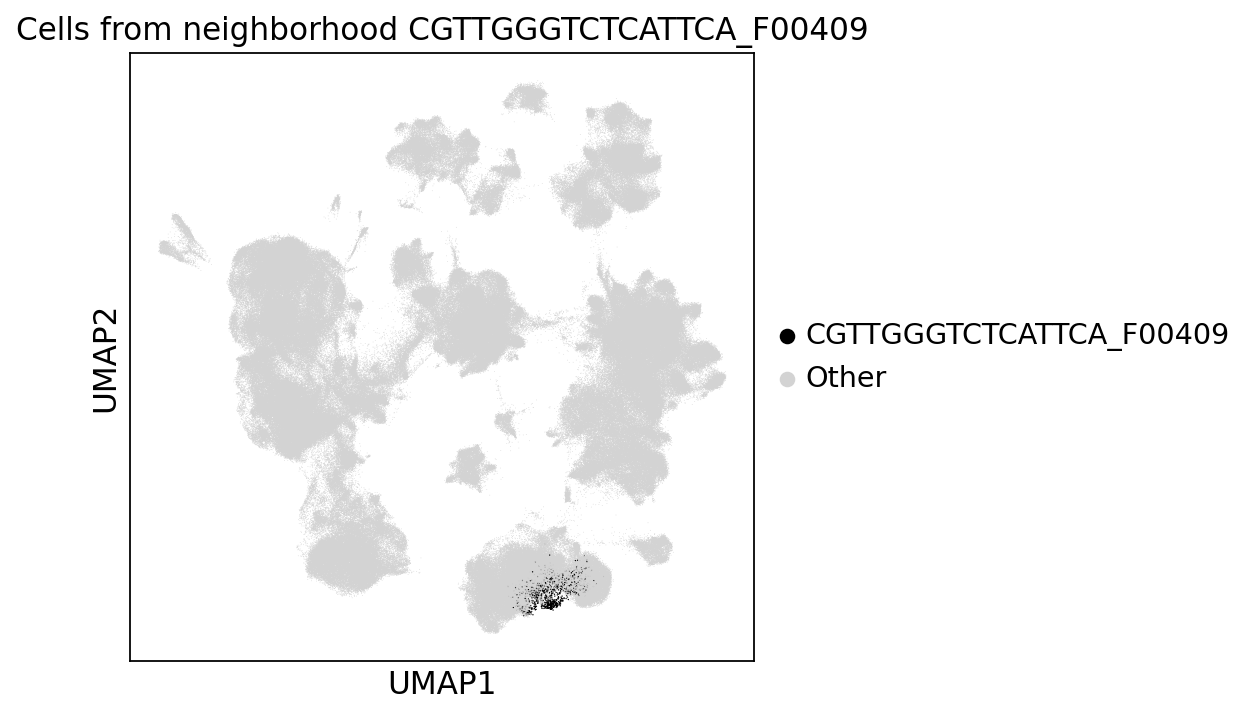

In [260]:
plotting.plot_umap_neighborhood(
    results_healthy, neighborhood="CGTTGGGTCTCATTCA_F00409", scale=0.5
)

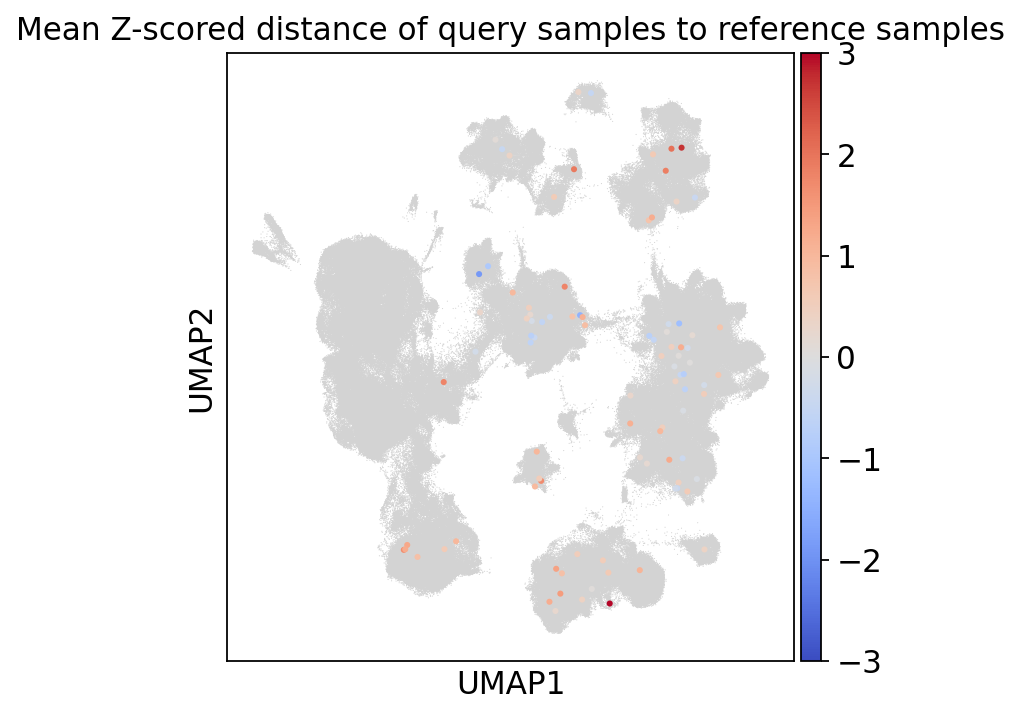

In [261]:
plotting.plot_umap_zscored_q_dist_to_ref(results_healthy)

#### disease:

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


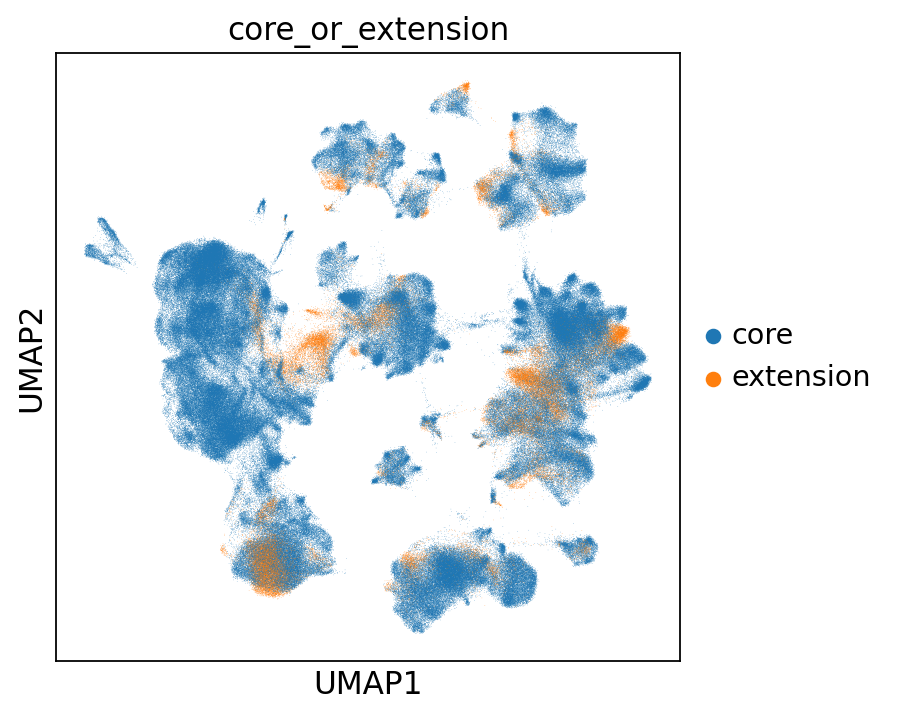

In [264]:
sc.pl.umap(results_disease.adata, color="core_or_extension")

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_basic/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


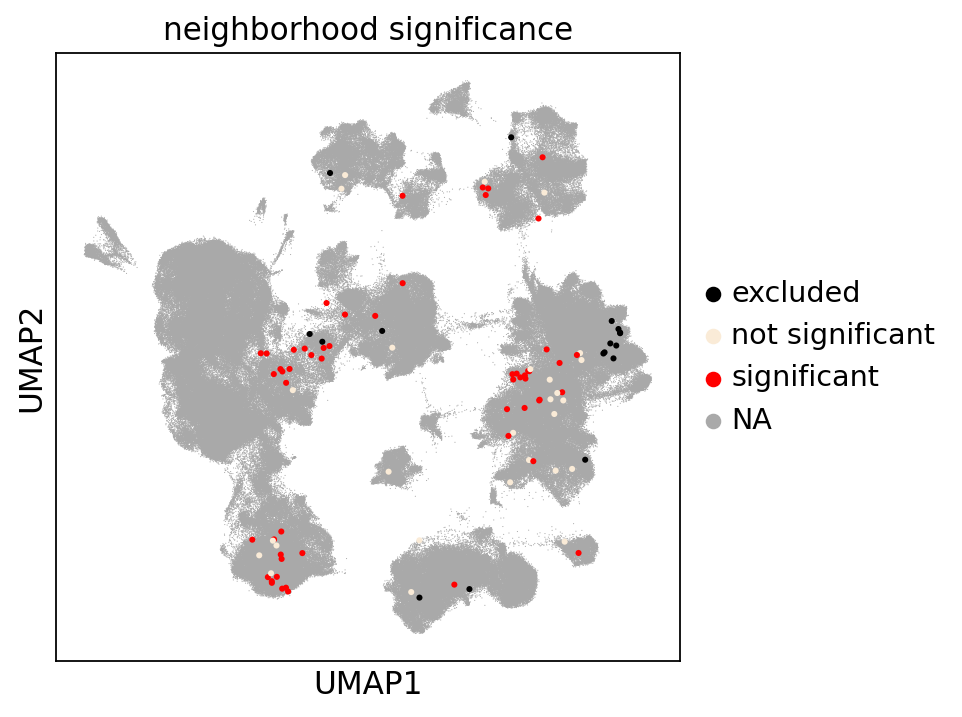

In [263]:
plotting.plot_umap_significance(results_disease)

In [ ]:
# plotting.plot_umap_neighborhood(
#     results_disease, neighborhood="...", scale=0.5
# )

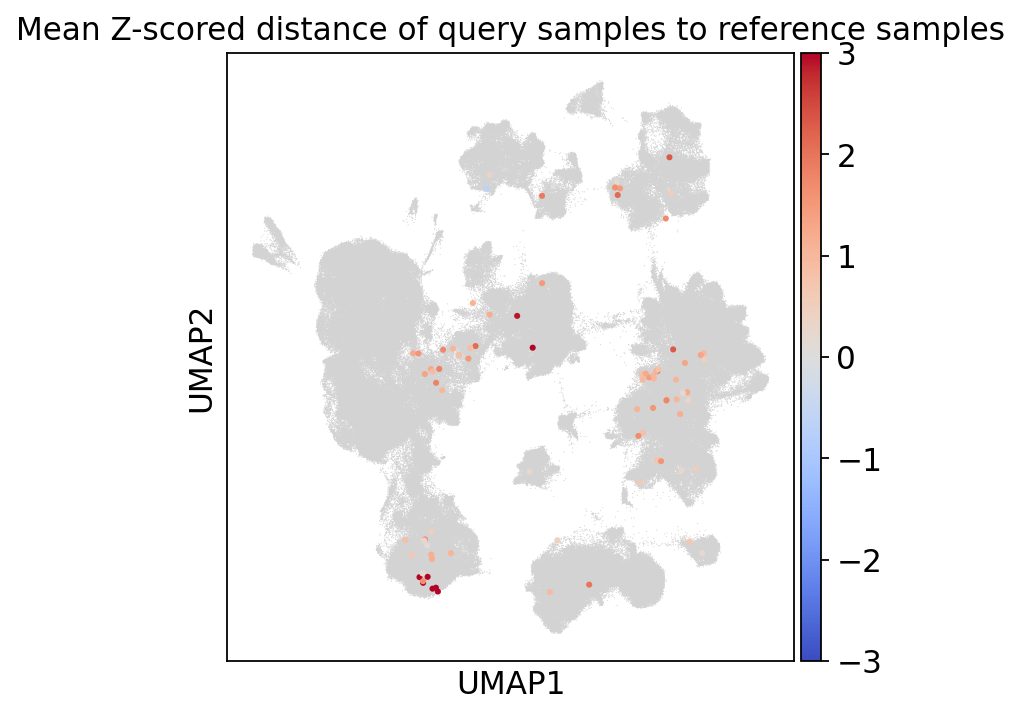

In [265]:
plotting.plot_umap_zscored_q_dist_to_ref(results_disease)

In [267]:
imp.reload(plotting)

<module 'plotting' from '../../../atlas_extension/mapqc/plotting.py'>

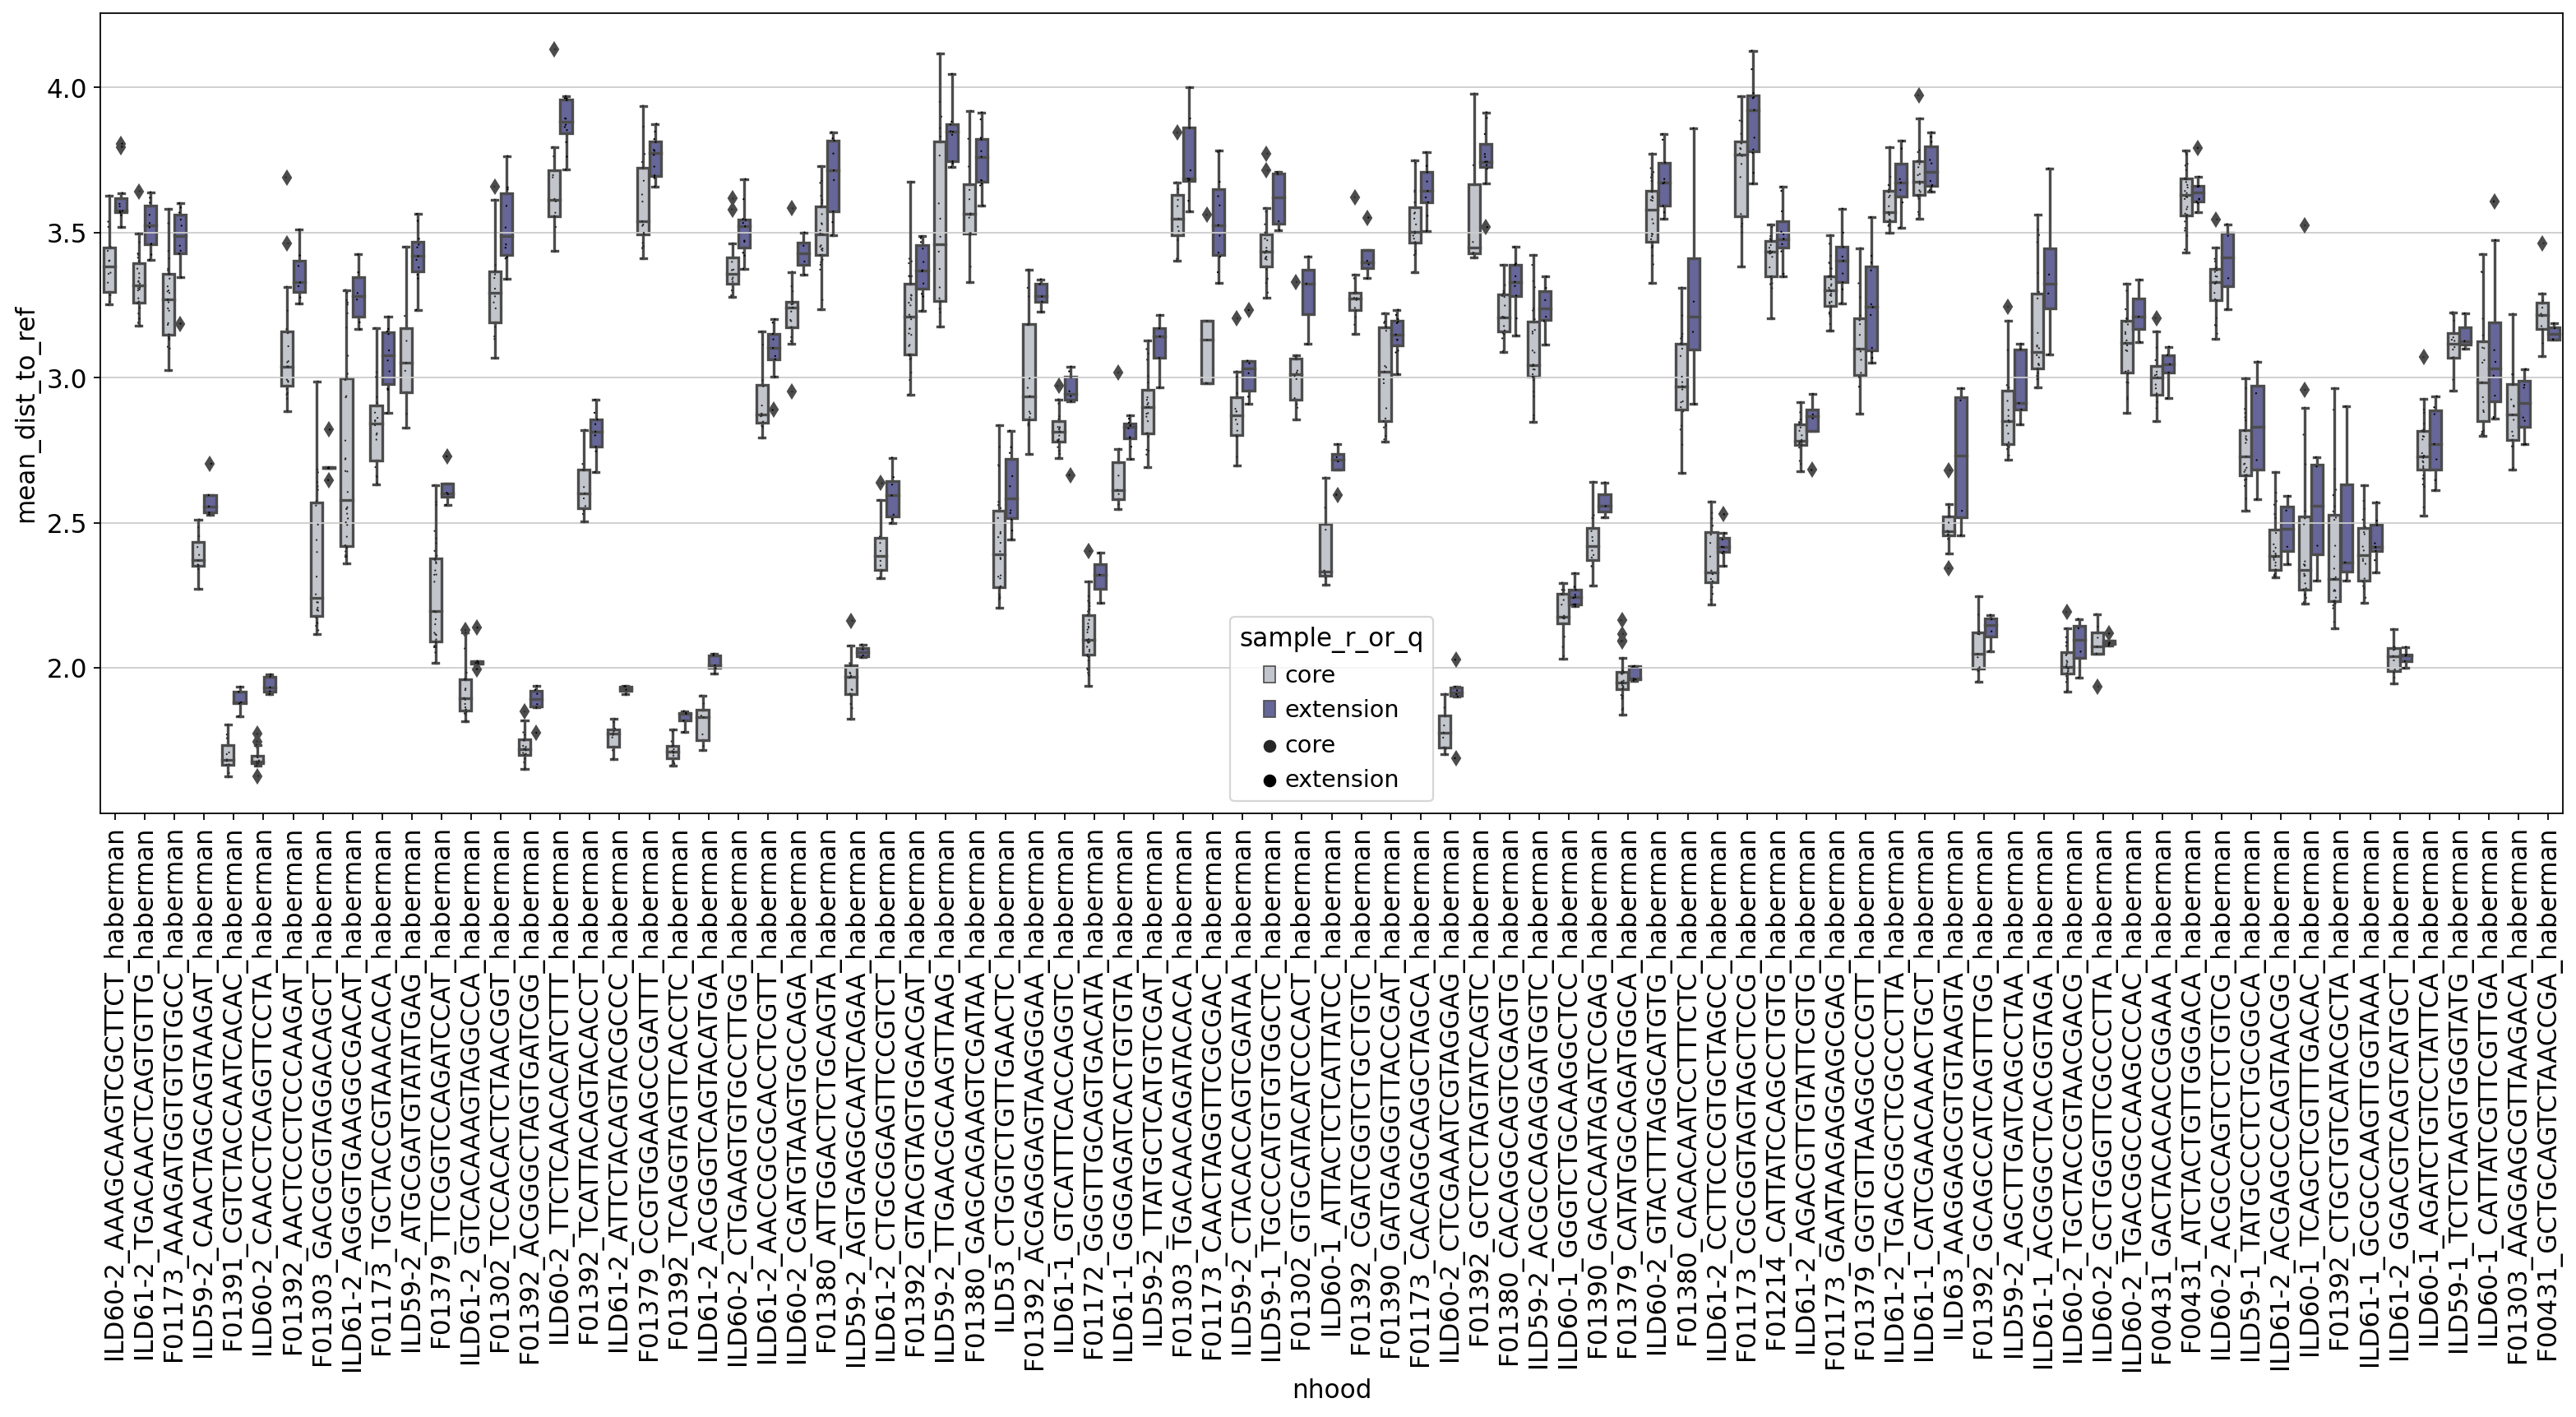

In [268]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(results_disease)

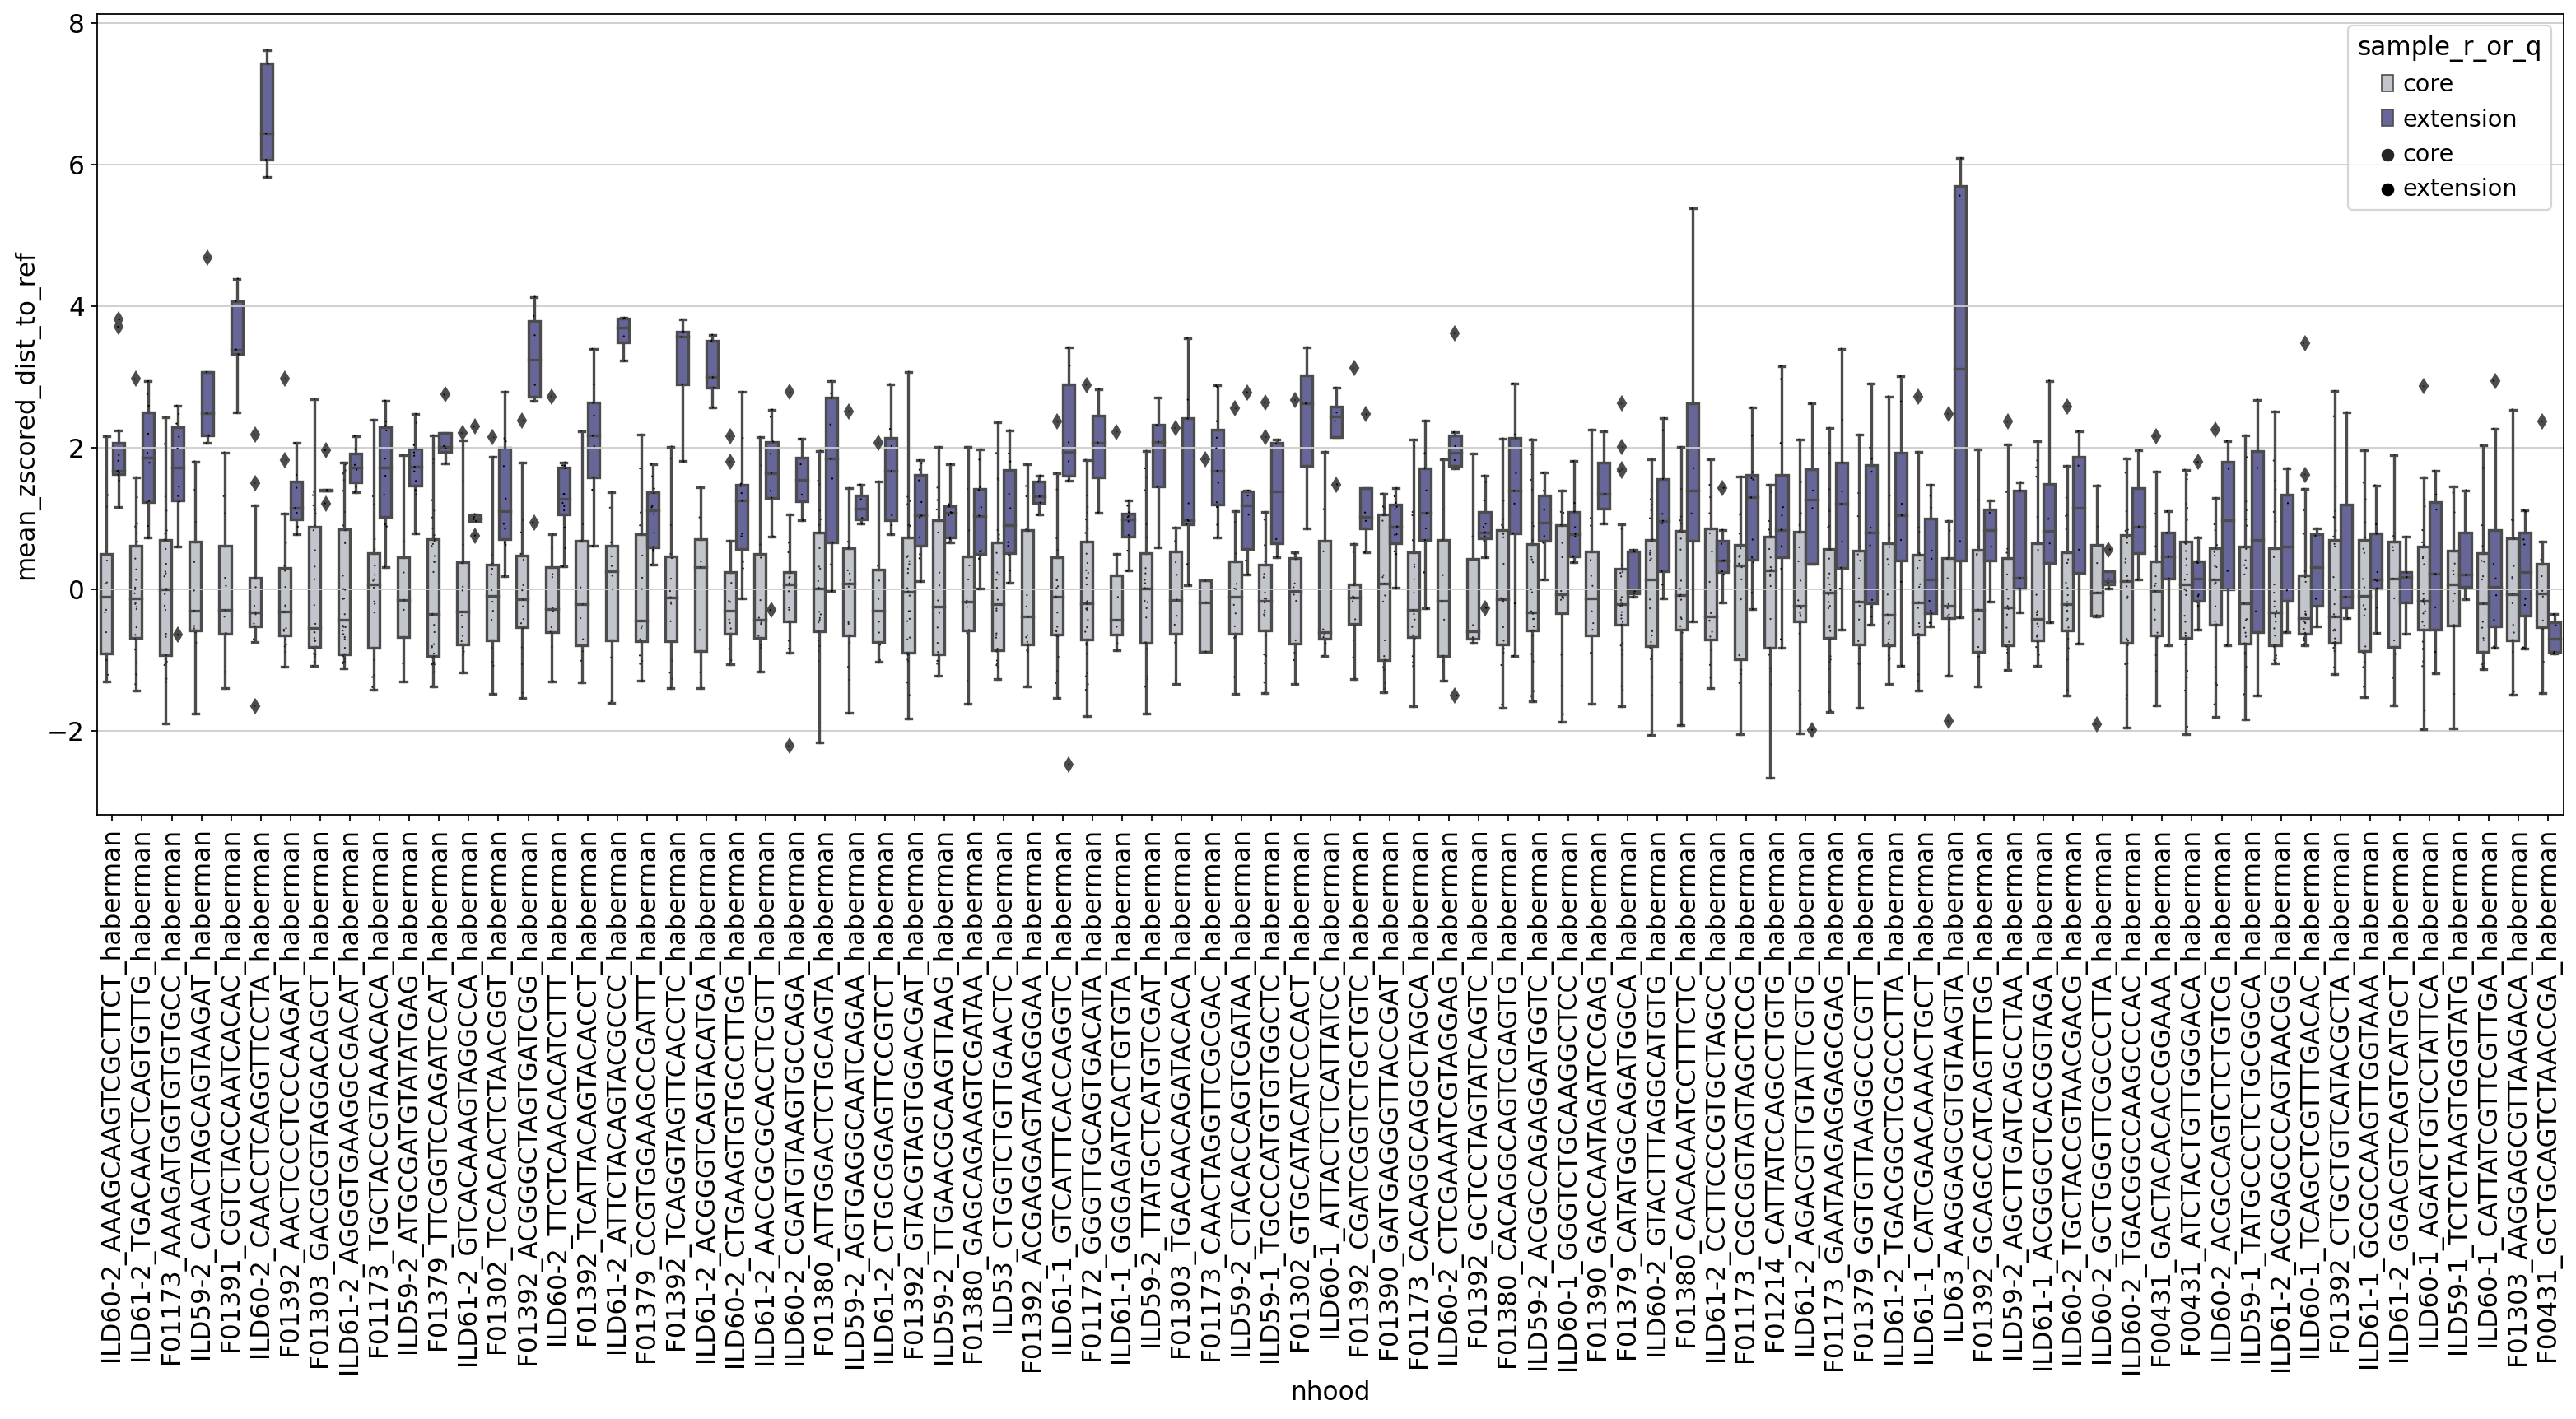

In [269]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(
    results_disease, use_zscored_dists=True
)

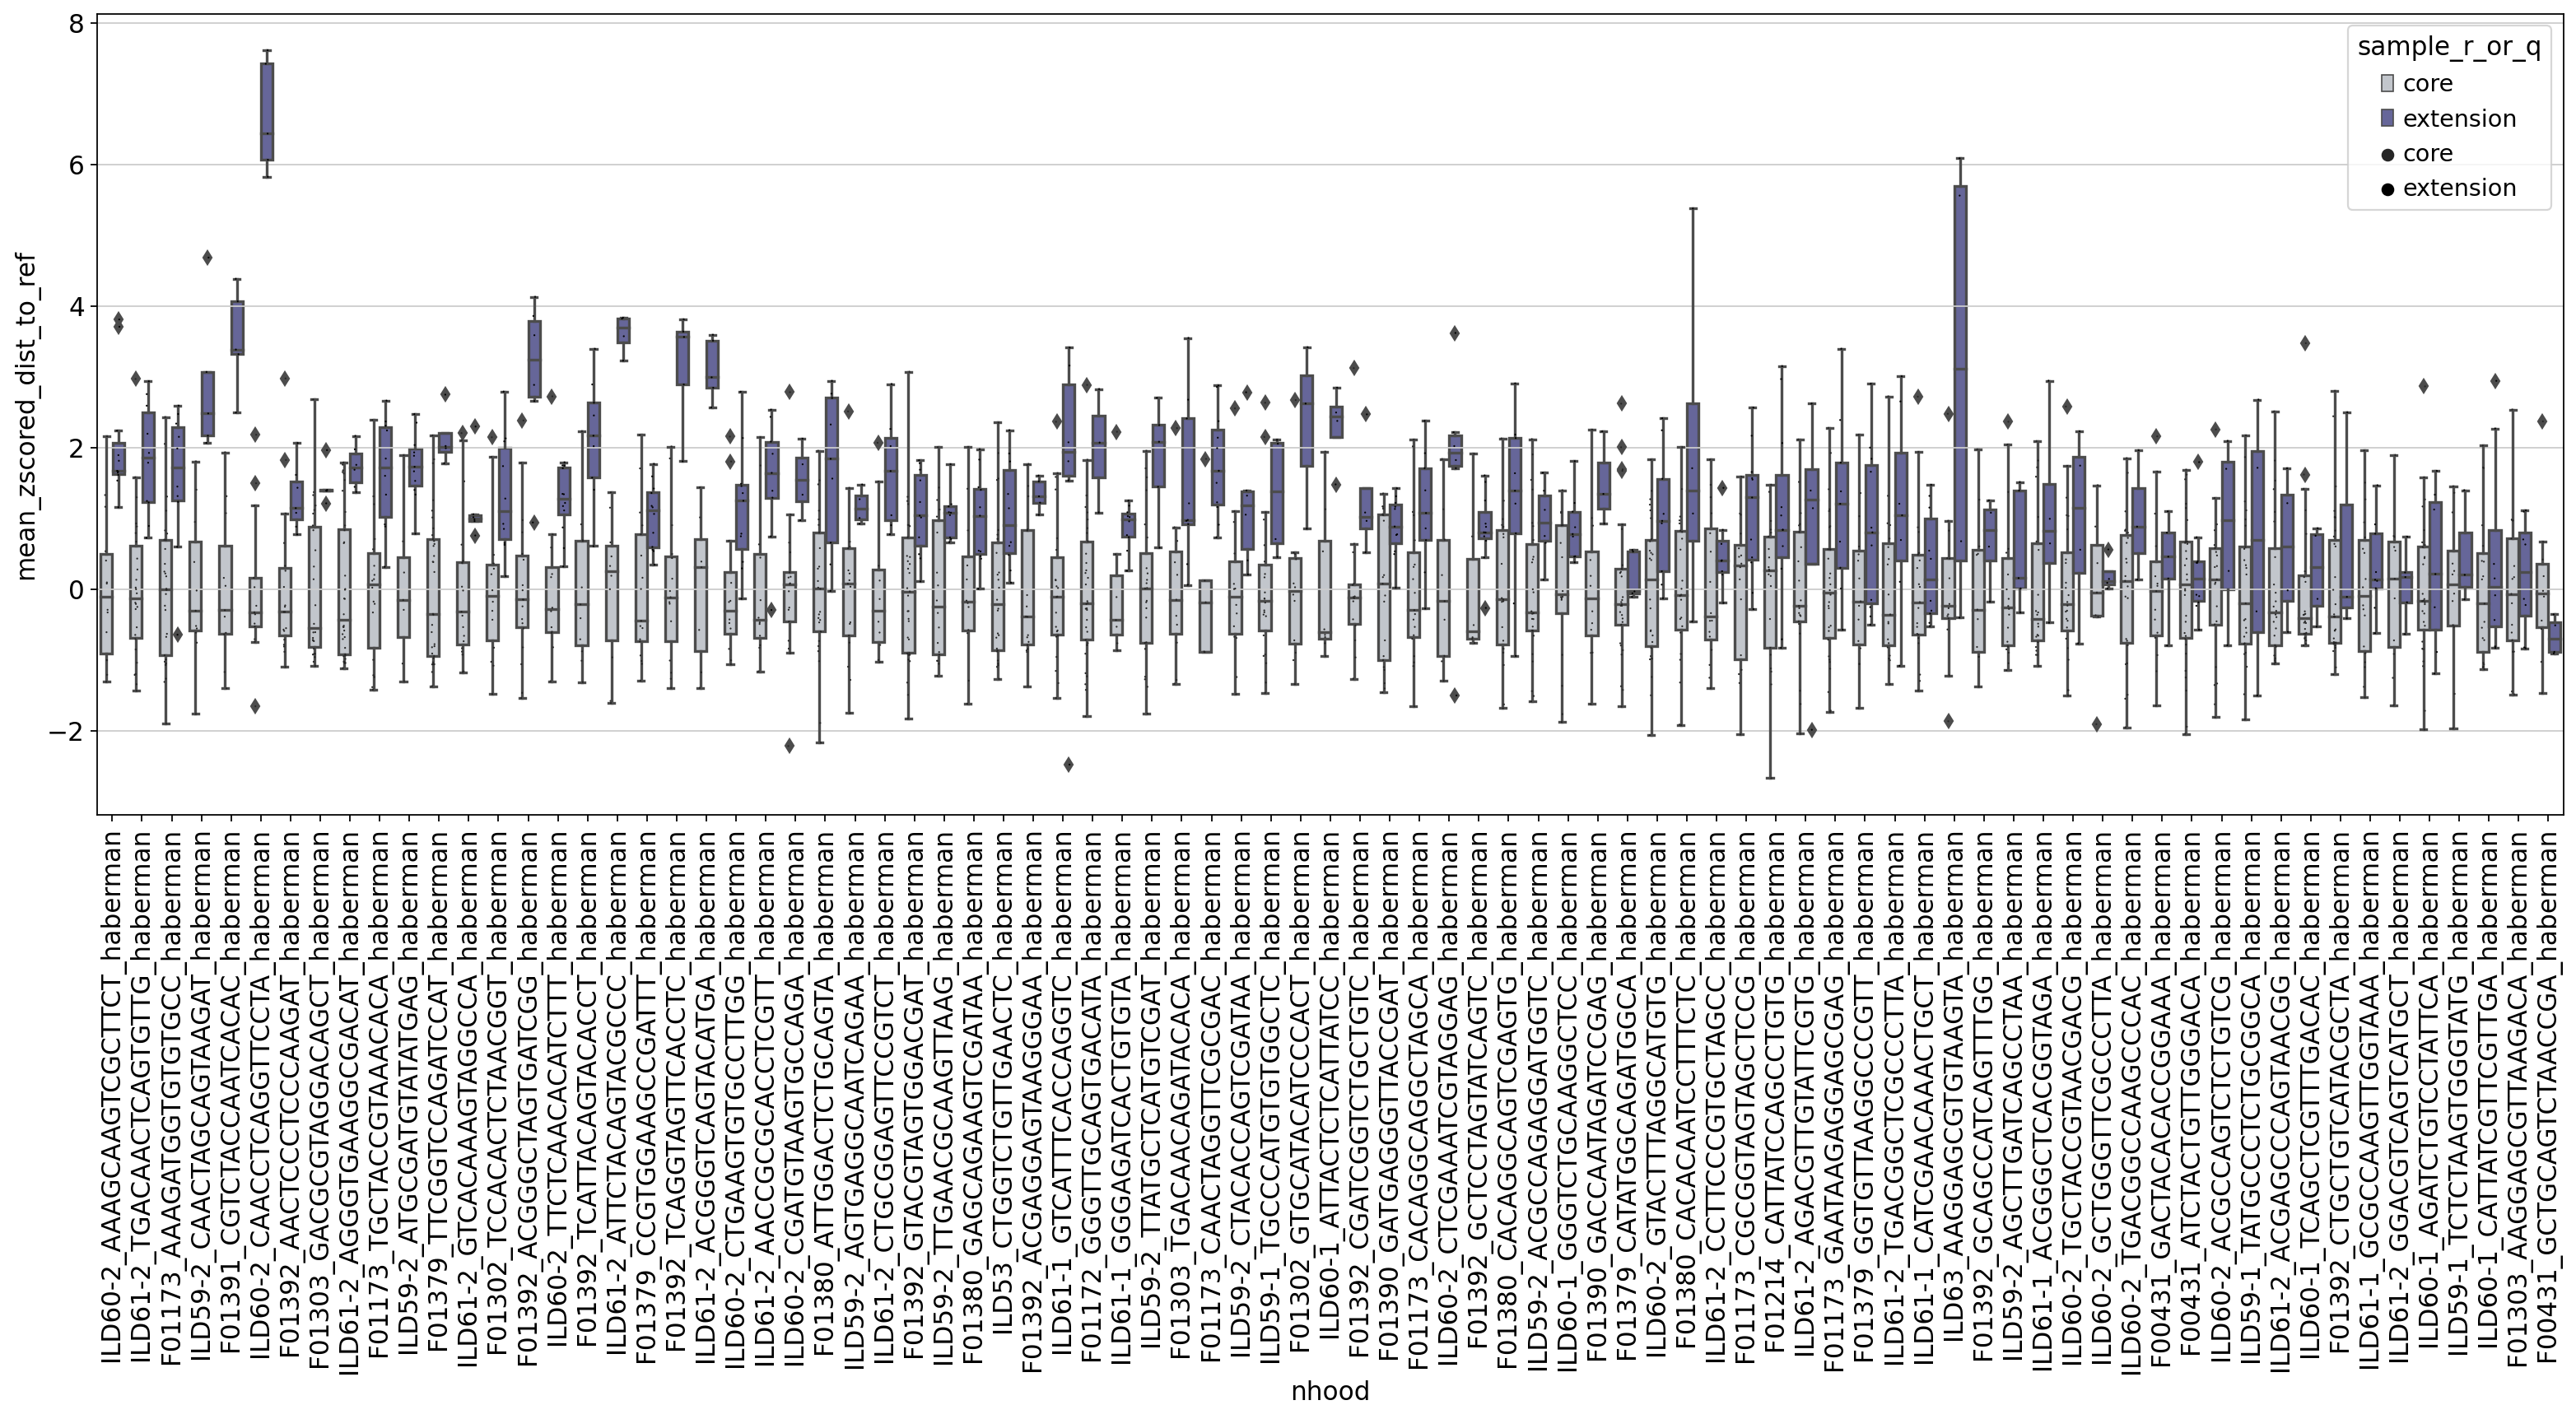

In [266]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(results_disease)

In [89]:
imp.reload(plotting)

<module 'plotting' from '../../../atlas_extension/mapqc/plotting.py'>

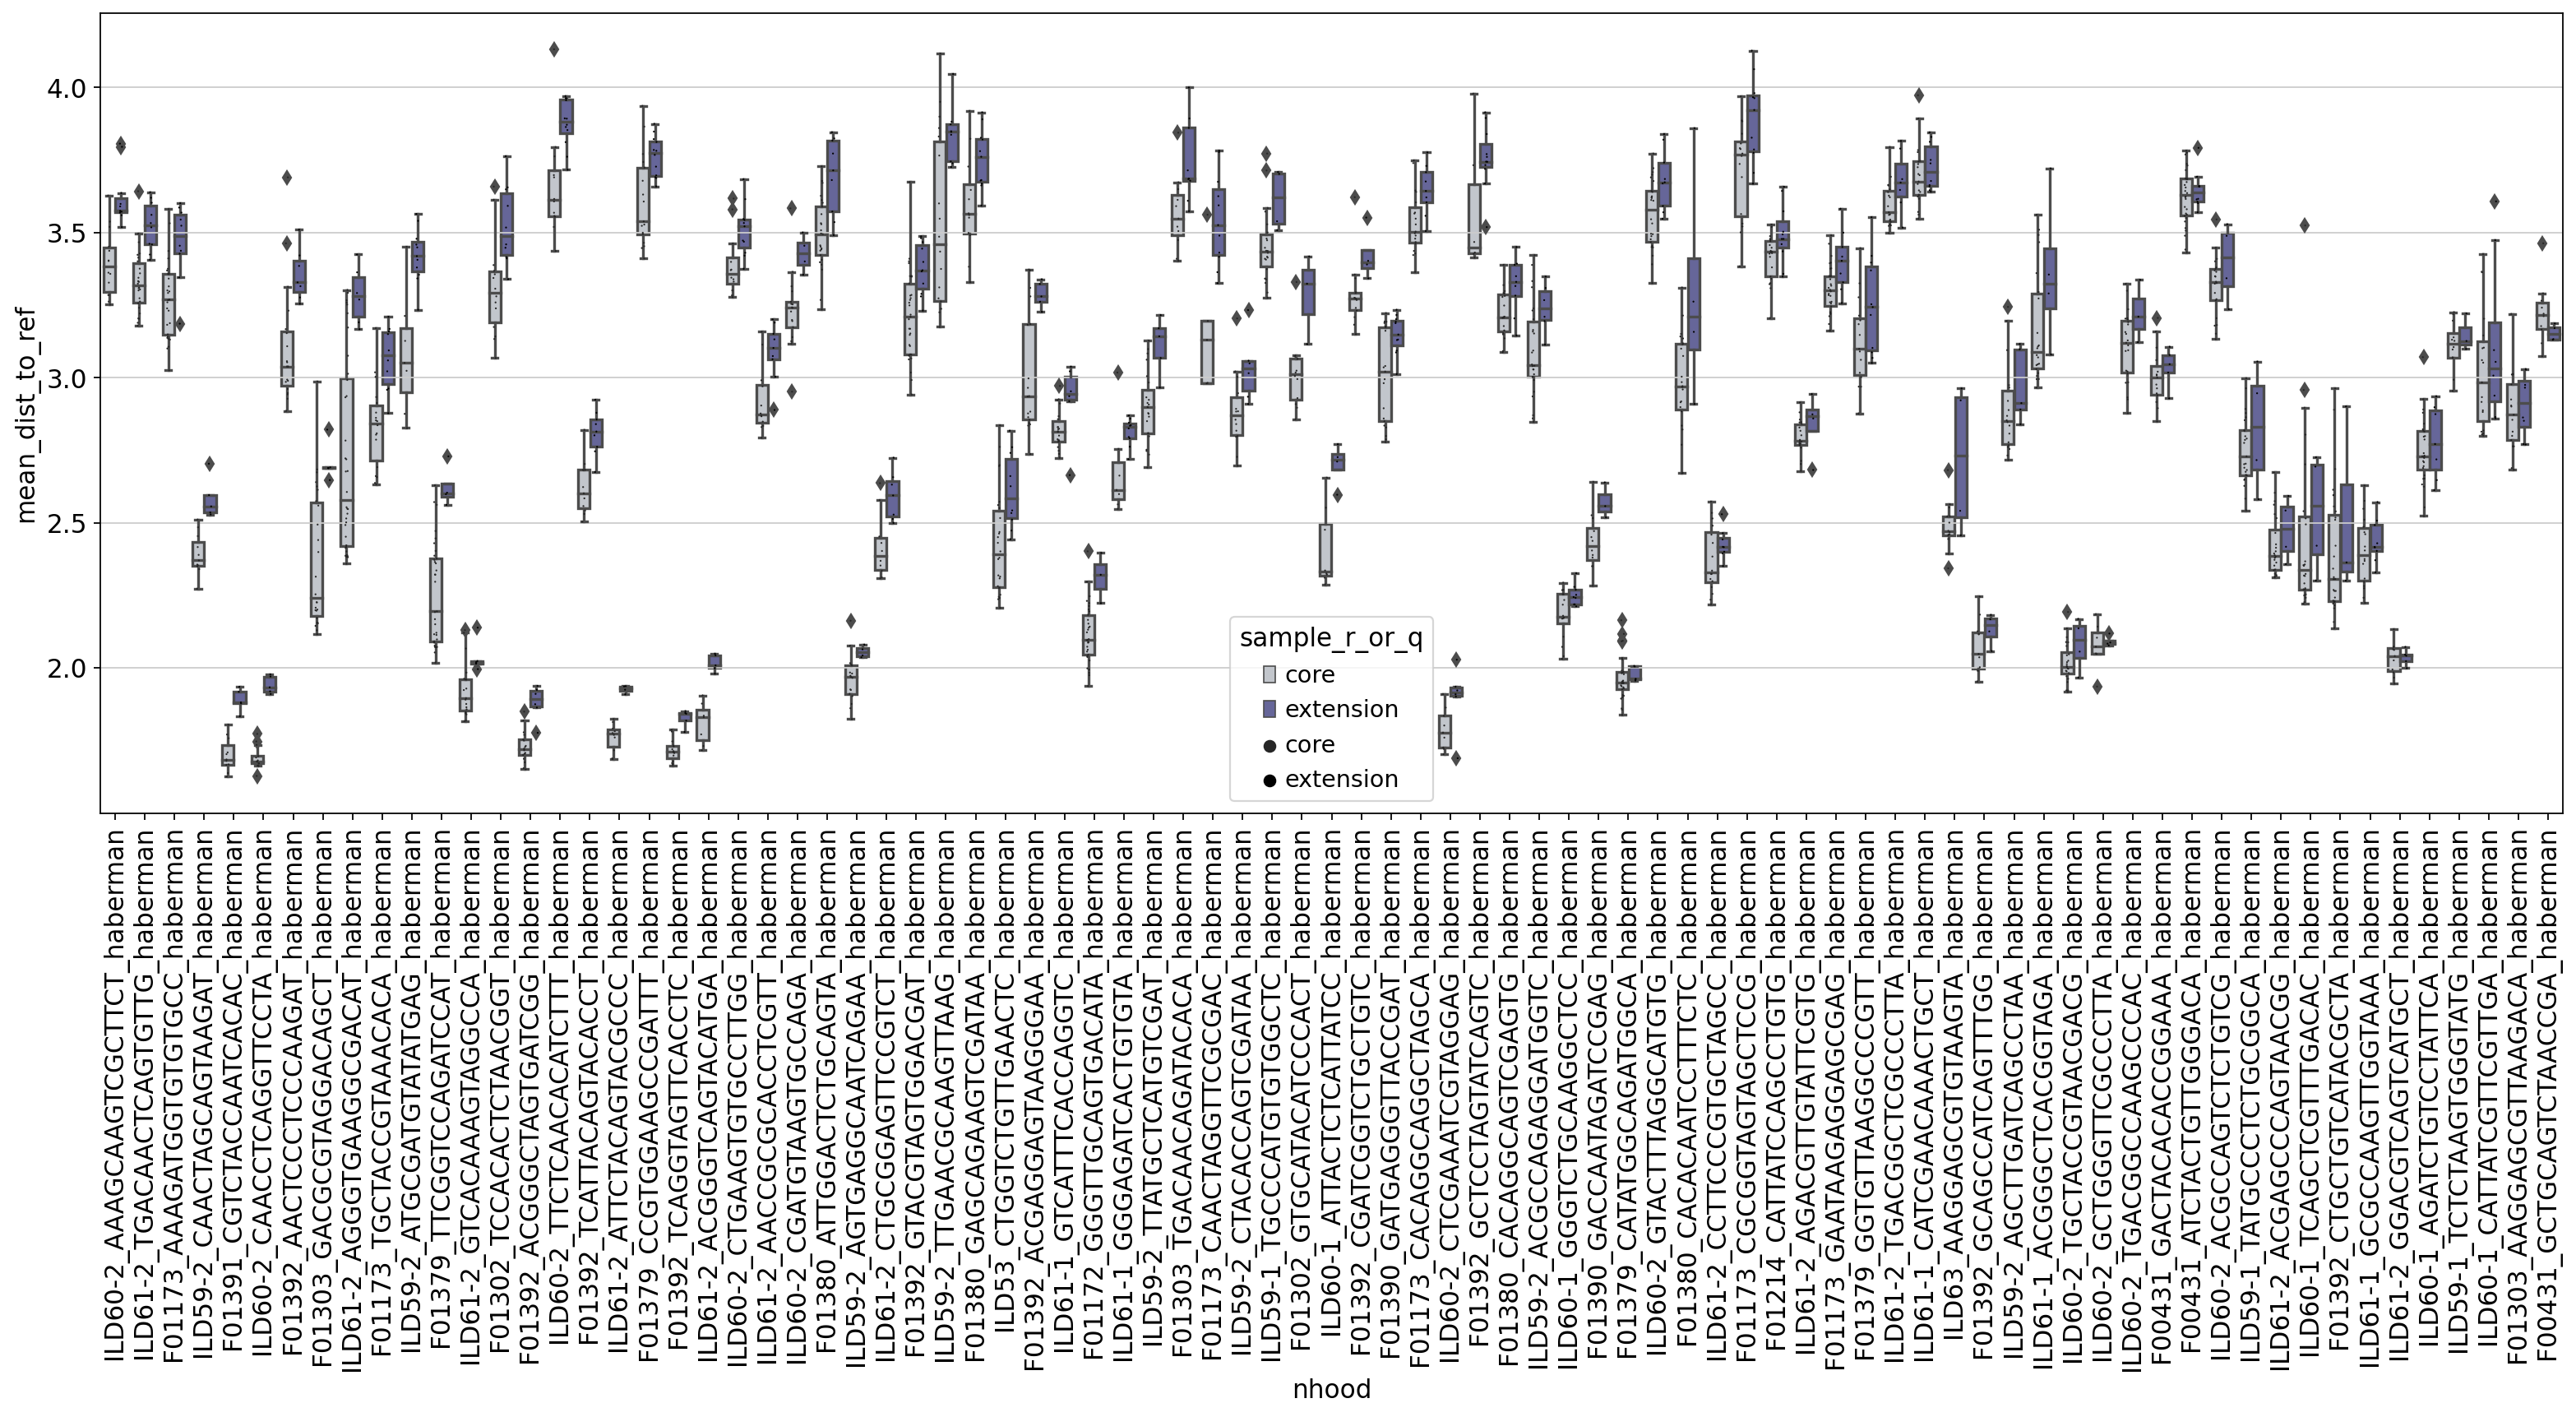

In [90]:
plotting.plot_boxplot_of_ref_vs_q_dists_per_nhood(results_disease)

### UMAP shaded by sample: